# 02 · Comparativa RNN simple vs LSTM vs GRU

Este notebook **no entrena nada**: carga los resultados guardados en `reports/results/` por el
pipeline (`tune` → `evaluate` → `timing` → `summarize`, ejecutado en la GPU) y los analiza.
Todas las métricas son fuera de muestra, en $/barril, sobre los mismos orígenes de previsión del
periodo de test (desde el 1-1-2022) para las tres redes y el modelo ingenuo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from oilcast.config import load_config
from oilcast.evaluation.report import comparison_table, stability_table, year_table
from oilcast.models.recurrent import ARCH_LABELS
from oilcast.paths import get_paths
from oilcast.training.tune import tuning_summary
from oilcast.utils import read_json

cfg = load_config()
paths = get_paths(cfg)
archs, horizons = cfg["architectures"], cfg["targets"]["horizons"]
comp = pd.read_csv(paths.results / "comparison.csv")
by_year = pd.read_csv(paths.results / "metrics_by_year.csv")
timing = pd.read_csv(paths.results / "timing.csv")
selection = read_json(paths.results / "selection.json")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

## 1. Diseño experimental

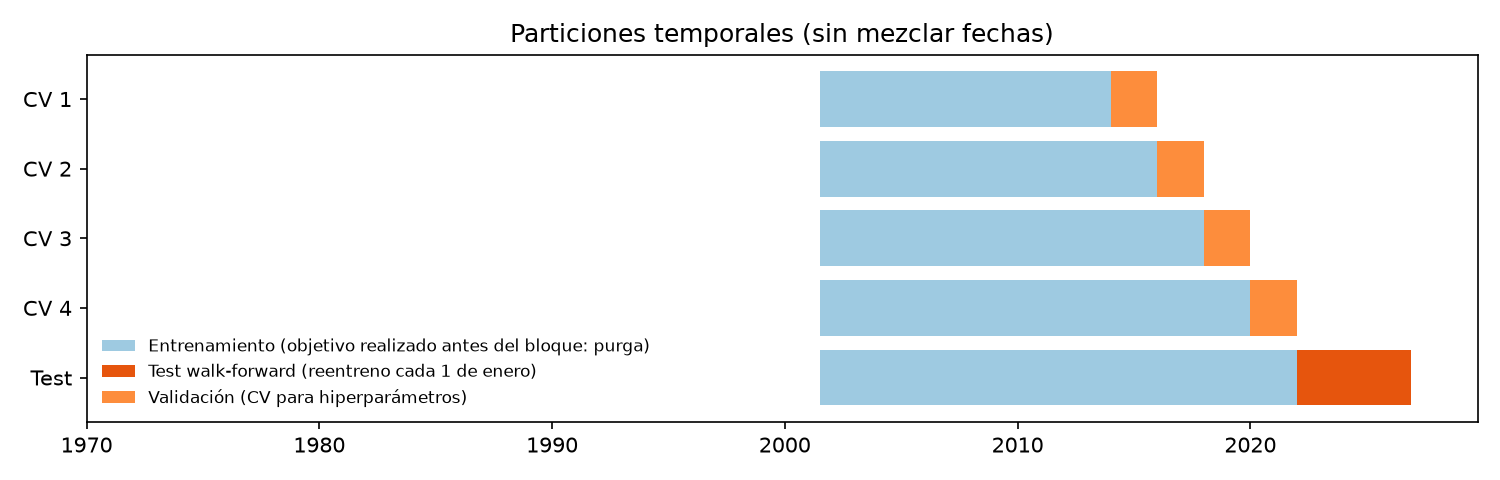

In [2]:
display(Image(paths.figures / "particiones.png"))

- **CV de hiperparámetros**: 4 bloques de validación de 2 años; para cada bloque se entrena solo
  con orígenes cuyo objetivo (precio a h días) ya se conoce antes de que empiece el bloque
  (*purga*). Optuna TPE, 80 trials por red y horizonte, misma semilla y mismo espacio
  (16-256 neuronas, 1-3 capas).
- **Sin deriva**: las redes aprenden desviaciones respecto a la media del entrenamiento, para que
  no proyecten al futuro la subida de 2001-2013.
- **Test**: reentreno cada 1 de enero (2022…2026) con todo lo realizado antes, hiperparámetros y
  nº de épocas fijados en la CV (sin *early stopping* sobre test), 5 semillas.
- **Recalibración del centro**: la mediana se encoge hacia el ingenuo con un factor en [0, 1]
  estimado con los errores ya conocidos en cada fecha.
- **Intervalos**: cuantiles 10-90 % de la red + calibración conformal con errores ya realizados
  antes de cada previsión.

Esta configuración es la adoptada tras dos rondas de experimentos (ver
`docs/experimento-ampliado.md` y `docs/experimento-ronda2.md`); los resultados de la
configuración original están en `reports/results/experiments/v0_original/`.

## 2. Hiperparámetros elegidos y pérdida de validación

In [3]:
tun = tuning_summary(paths, archs, horizons)
folds = {
    f"{a}_h{h}": read_json(paths.tuning_dir(a, h) / "best.json") for a in archs for h in horizons
}
tun.assign(
    pinball_por_fold=[
        np.round(folds[f"{r.arch}_h{r.horizon}"]["fold_losses"], 3).tolist()
        for r in tun.itertuples()
    ]
).round(4)

,arch,horizon,cv_pinball,final_epochs,n_trials,n_pruned,hidden_size,num_layers,dropout,lr,weight_decay,batch_size,pinball_por_fold
0,rnn,5,0.2464,25,80,31,64,1,0.4978,0.0006,0.0000,128,"[0.2, 0.221, 0.177, 0.387]"
1,rnn,63,0.2736,7,80,30,64,3,0.4192,0.0021,0.0000,256,"[0.331, 0.143, 0.195, 0.425]"
2,rnn,252,0.2556,10,80,27,256,2,0.4689,0.0025,0.0100,128,"[0.455, 0.105, 0.179, 0.283]"
3,lstm,5,0.2450,3,80,40,256,3,0.0859,0.0009,0.0005,128,"[0.195, 0.218, 0.18, 0.387]"
4,lstm,63,0.2885,4,80,20,64,3,0.3206,0.0021,0.0001,256,"[0.351, 0.149, 0.182, 0.473]"
5,lstm,252,0.3065,2,80,38,64,3,0.3264,0.0014,0.0001,128,"[0.568, 0.12, 0.199, 0.339]"
6,gru,5,0.2459,2,80,35,256,3,0.4684,0.0029,0.0097,128,"[0.199, 0.22, 0.179, 0.385]"
7,gru,63,0.2954,37,80,28,32,2,0.4606,0.0001,0.0000,64,"[0.4, 0.154, 0.182, 0.444]"
8,gru,252,0.3099,2,80,28,64,3,0.4664,0.0017,0.0001,256,"[0.64, 0.12, 0.188, 0.292]"


## 3. Tabla comparativa en test

In [4]:
display(Markdown(comparison_table(comp, horizons, archs)))

| Horizonte | Modelo | MAE ($) | RMSE ($) | R² | Mejora MAE vs ingenuo | Mejora RMSE vs ingenuo | p-valor DM | Acierto direccional | Cobertura IC80 | Anchura IC80 ($) | Winkler IC80 | Parámetros | Tiempo entren. (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Corto (5 d) | Ingenuo | 3.99 | 5.74 | 0.875 | — | — | — | — | 76.1 % | 10.61 | 19.93 | — | — |
| Corto (5 d) | RNN simple | 3.95 | 5.70 | 0.876 | +0.9 % | +0.6 % | 0.224 | 53.3 % | 79.0 % | 11.04 | 19.03 | 5959 | 0.9 |
| Corto (5 d) | LSTM | 3.99 | 5.74 | 0.875 | +0.0 % | +0.0 % | — | — | 75.9 % | 10.83 | 18.91 | 1339143 | 0.6 |
| Corto (5 d) | GRU | 3.98 | 5.73 | 0.875 | +0.1 % | +0.1 % | 0.372 | 50.7 % | 81.1 % | 11.98 | 19.12 | 1004807 | 0.4 |
| Medio (63 d) | Ingenuo | 11.94 | 17.44 | -0.207 | — | — | — | — | 84.5 % | 38.45 | 65.21 | — | — |
| Medio (63 d) | RNN simple | 11.47 | 17.12 | -0.163 | +4.0 % | +1.8 % | 0.118 | 59.2 % | 87.7 % | 49.66 | 75.72 | 22599 | 0.2 |
| Medio (63 d) | LSTM | 11.55 | 17.32 | -0.191 | +3.3 % | +0.7 % | 0.839 | 60.0 % | 85.7 % | 45.53 | 72.82 | 89031 | 0.2 |
| Medio (63 d) | GRU | 11.30 | 17.01 | -0.148 | +5.4 % | +2.4 % | 0.487 | 65.3 % | 88.2 % | 48.62 | 75.32 | 11751 | 3.2 |
| Largo (252 d) | Ingenuo | 16.50 | 22.53 | -1.466 | — | — | — | — | 93.3 % | 89.74 | 97.12 | — | — |
| Largo (252 d) | RNN simple | 17.63 | 27.06 | -2.559 | -6.8 % | -20.1 % | 0.120 | 54.3 % | 89.7 % | 113.94 | 128.91 | 204551 | 0.7 |
| Largo (252 d) | LSTM | 20.24 | 27.52 | -2.682 | -22.7 % | -22.2 % | 0.033 | 52.6 % | 88.7 % | 104.82 | 125.67 | 89031 | 0.1 |
| Largo (252 d) | GRU | 16.61 | 24.73 | -1.972 | -0.7 % | -9.8 % | 0.198 | 54.8 % | 95.3 % | 133.76 | 137.71 | 66887 | 0.1 |

*Mejora* = 1 − error del modelo / error del ingenuo. *p-valor DM*: Diebold-Mariano con varianza
HAC (h−1 retardos) sobre el error cuadrático. Cobertura y anchura del intervalo del 80 % tras la
calibración conformal (el ingenuo usa los cuantiles históricos de las variaciones a h días).

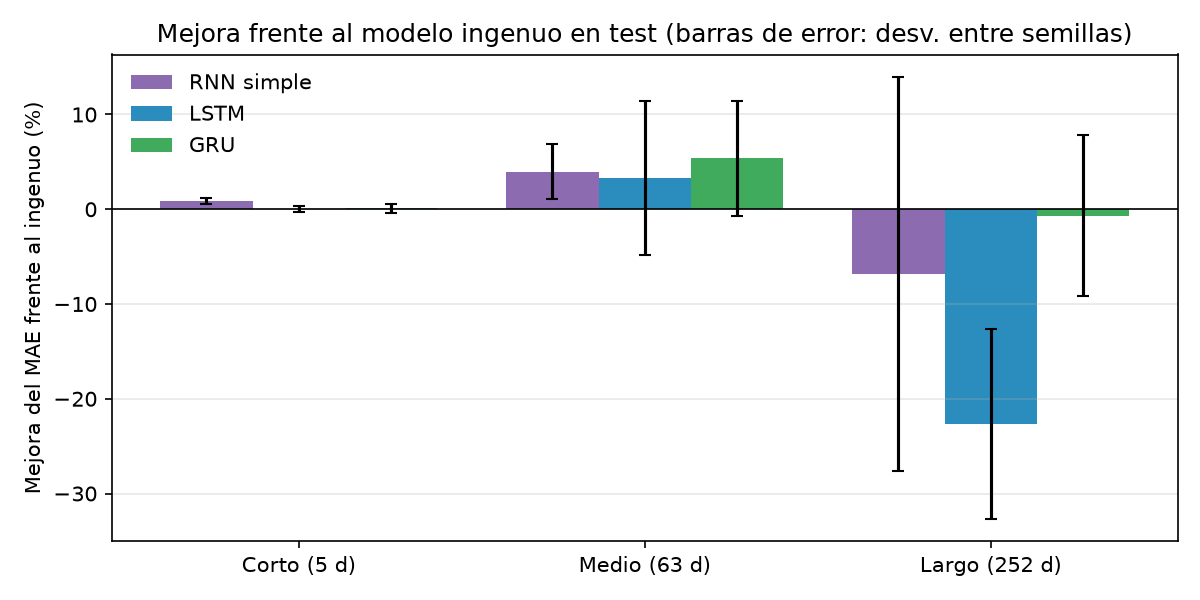

In [5]:
display(Image(paths.figures / "mejora_vs_ingenuo.png"))

## 4. Estabilidad entre semillas y calibración del intervalo

In [6]:
display(Markdown(stability_table(comp, horizons, archs)))

| Horizonte | Modelo | MAE ensemble | MAE por semilla (media ± desv.) | Mejora MAE por semilla (desv.) | Cobertura IC80 sin calibrar | MSE |
|---|---|---|---|---|---|---|
| Corto (5 d) | RNN simple | 3.95 | 3.94 ± 0.01 | 0.3 % | 73.8 % | 32.5 |
| Corto (5 d) | LSTM | 3.99 | 3.99 ± 0.01 | 0.3 % | 73.8 % | 32.9 |
| Corto (5 d) | GRU | 3.98 | 3.99 ± 0.02 | 0.5 % | 77.4 % | 32.9 |
| Medio (63 d) | RNN simple | 11.47 | 11.52 ± 0.35 | 2.9 % | 77.5 % | 293.0 |
| Medio (63 d) | LSTM | 11.55 | 13.63 ± 0.97 | 8.1 % | 71.3 % | 300.0 |
| Medio (63 d) | GRU | 11.30 | 14.10 ± 0.72 | 6.0 % | 71.0 % | 289.4 |
| Largo (252 d) | RNN simple | 17.63 | 19.80 ± 3.44 | 20.8 % | 77.9 % | 732.3 |
| Largo (252 d) | LSTM | 20.24 | 22.59 ± 1.66 | 10.0 % | 69.4 % | 757.5 |
| Largo (252 d) | GRU | 16.61 | 22.52 ± 1.40 | 8.5 % | 76.6 % | 611.4 |


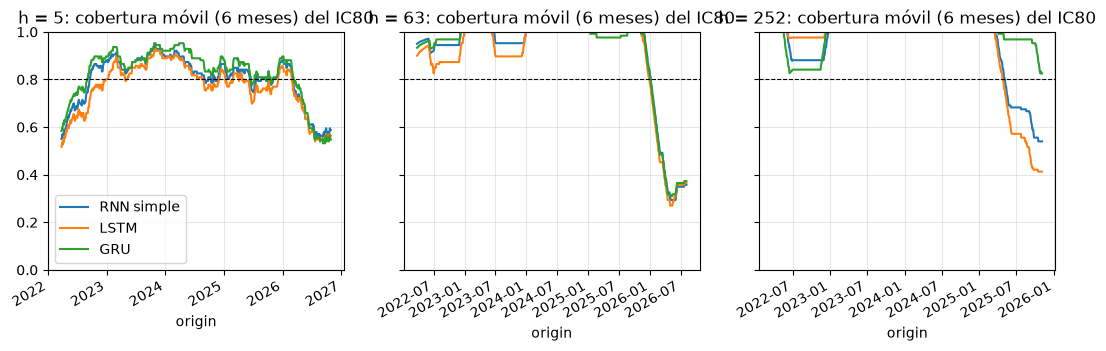

In [7]:
fig, axes = plt.subplots(1, len(horizons), figsize=(13, 3.5), sharey=True)
for ax, h in zip(axes, horizons, strict=True):
    for a in archs:
        e = pd.read_csv(
            paths.results / "predictions" / f"{a}_h{h}_ensemble.csv", parse_dates=["origin"]
        )
        t = e[e["phase"] == "test"].set_index("origin")
        inside = ((t["y"] >= t["lo80"]) & (t["y"] <= t["hi80"])).astype(float)
        inside.rolling(126, min_periods=60).mean().plot(ax=ax, label=ARCH_LABELS[a])
    ax.axhline(0.8, color="black", ls="--", lw=0.8)
    ax.set_title(f"h = {h}: cobertura móvil (6 meses) del IC80")
axes[0].legend()
axes[0].set_ylim(0, 1);

## 5. ¿Cuándo aporta valor? Resultados por año

In [8]:
display(Markdown(year_table(by_year, horizons, archs)))

| Horizonte | Modelo | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|
| Corto (5 d) | RNN simple | +1.6 % | +0.6 % | +2.0 % | +1.1 % | -0.1 % |
| Corto (5 d) | LSTM | +0.0 % | +0.0 % | +0.0 % | +0.0 % | +0.0 % |
| Corto (5 d) | GRU | +0.2 % | -0.1 % | +0.3 % | -0.0 % | +0.0 % |
| Corto (5 d) | MAE ingenuo ($) | 5.35 | 3.00 | 2.36 | 2.39 | 7.45 |
| Medio (63 d) | RNN simple | +8.8 % | +3.2 % | +9.7 % | -1.1 % | +2.1 % |
| Medio (63 d) | LSTM | -5.4 % | -1.1 % | +30.1 % | +4.7 % | +3.6 % |
| Medio (63 d) | GRU | +23.4 % | -16.6 % | +5.3 % | +5.8 % | +2.9 % |
| Medio (63 d) | MAE ingenuo ($) | 12.94 | 8.62 | 4.82 | 9.07 | 32.75 |
| Largo (252 d) | RNN simple | -26.9 % | -4.1 % | +64.1 % | -24.7 % | — |
| Largo (252 d) | LSTM | -18.8 % | -141.3 % | +62.8 % | -29.0 % | — |
| Largo (252 d) | GRU | -11.1 % | -15.6 % | +51.6 % | -12.1 % | — |
| Largo (252 d) | MAE ingenuo ($) | 19.32 | 7.61 | 11.43 | 29.64 | — |


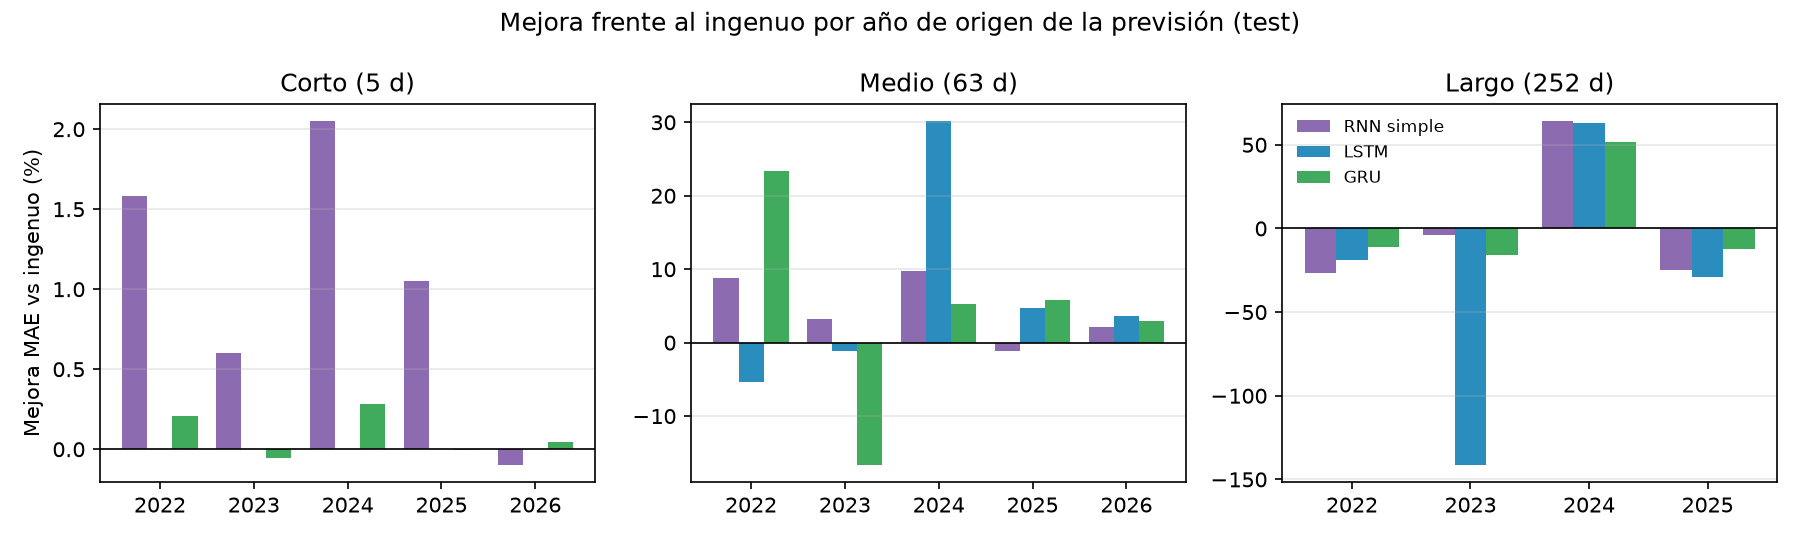

In [9]:
display(Image(paths.figures / "mejora_por_anio.png"))

## 6. ¿Qué predice realmente la red?

La mediana prevista por la red frente a la variación realizada. Una nube centrada cerca de 0 en
el eje vertical indica que la red ha aprendido que la mejor apuesta central es «casi sin cambio»
(y pone su valor en el rango); una pendiente clara indicaría capacidad direccional.

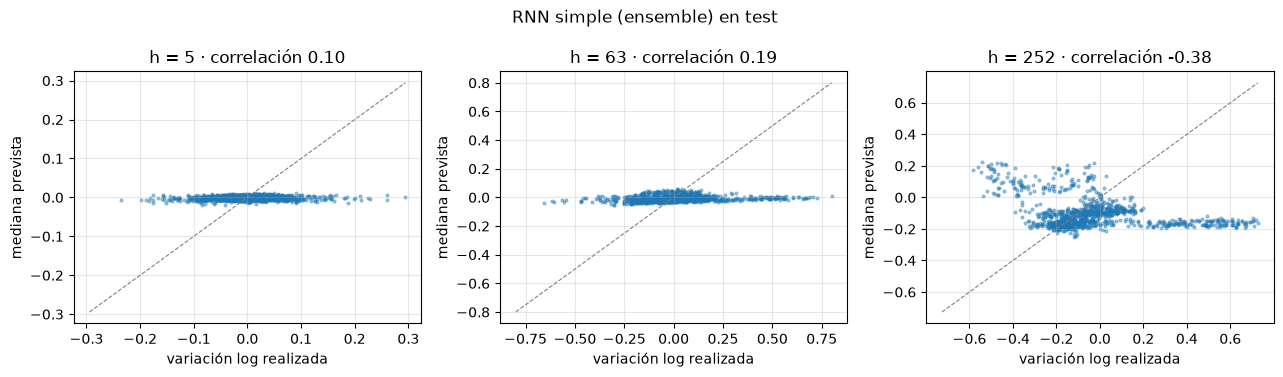

In [10]:
chosen = selection["chosen"]
fig, axes = plt.subplots(1, len(horizons), figsize=(13, 3.8))
for ax, h in zip(axes, horizons, strict=True):
    e = pd.read_csv(paths.results / "predictions" / f"{chosen}_h{h}_ensemble.csv")
    t = e[e["phase"] == "test"]
    ax.scatter(t["y"], t["q50"], s=4, alpha=0.4)
    lim = np.abs(t["y"]).max()
    ax.plot([-lim, lim], [-lim, lim], color="grey", lw=0.8, ls="--")
    rho = np.corrcoef(t["y"], t["q50"])[0, 1]
    ax.set_title(f"h = {h} · correlación {rho:.2f}")
    ax.set_xlabel("variación log realizada")
    ax.set_ylabel("mediana prevista")
fig.suptitle(f"{ARCH_LABELS[chosen]} (ensemble) en test")
fig.tight_layout();

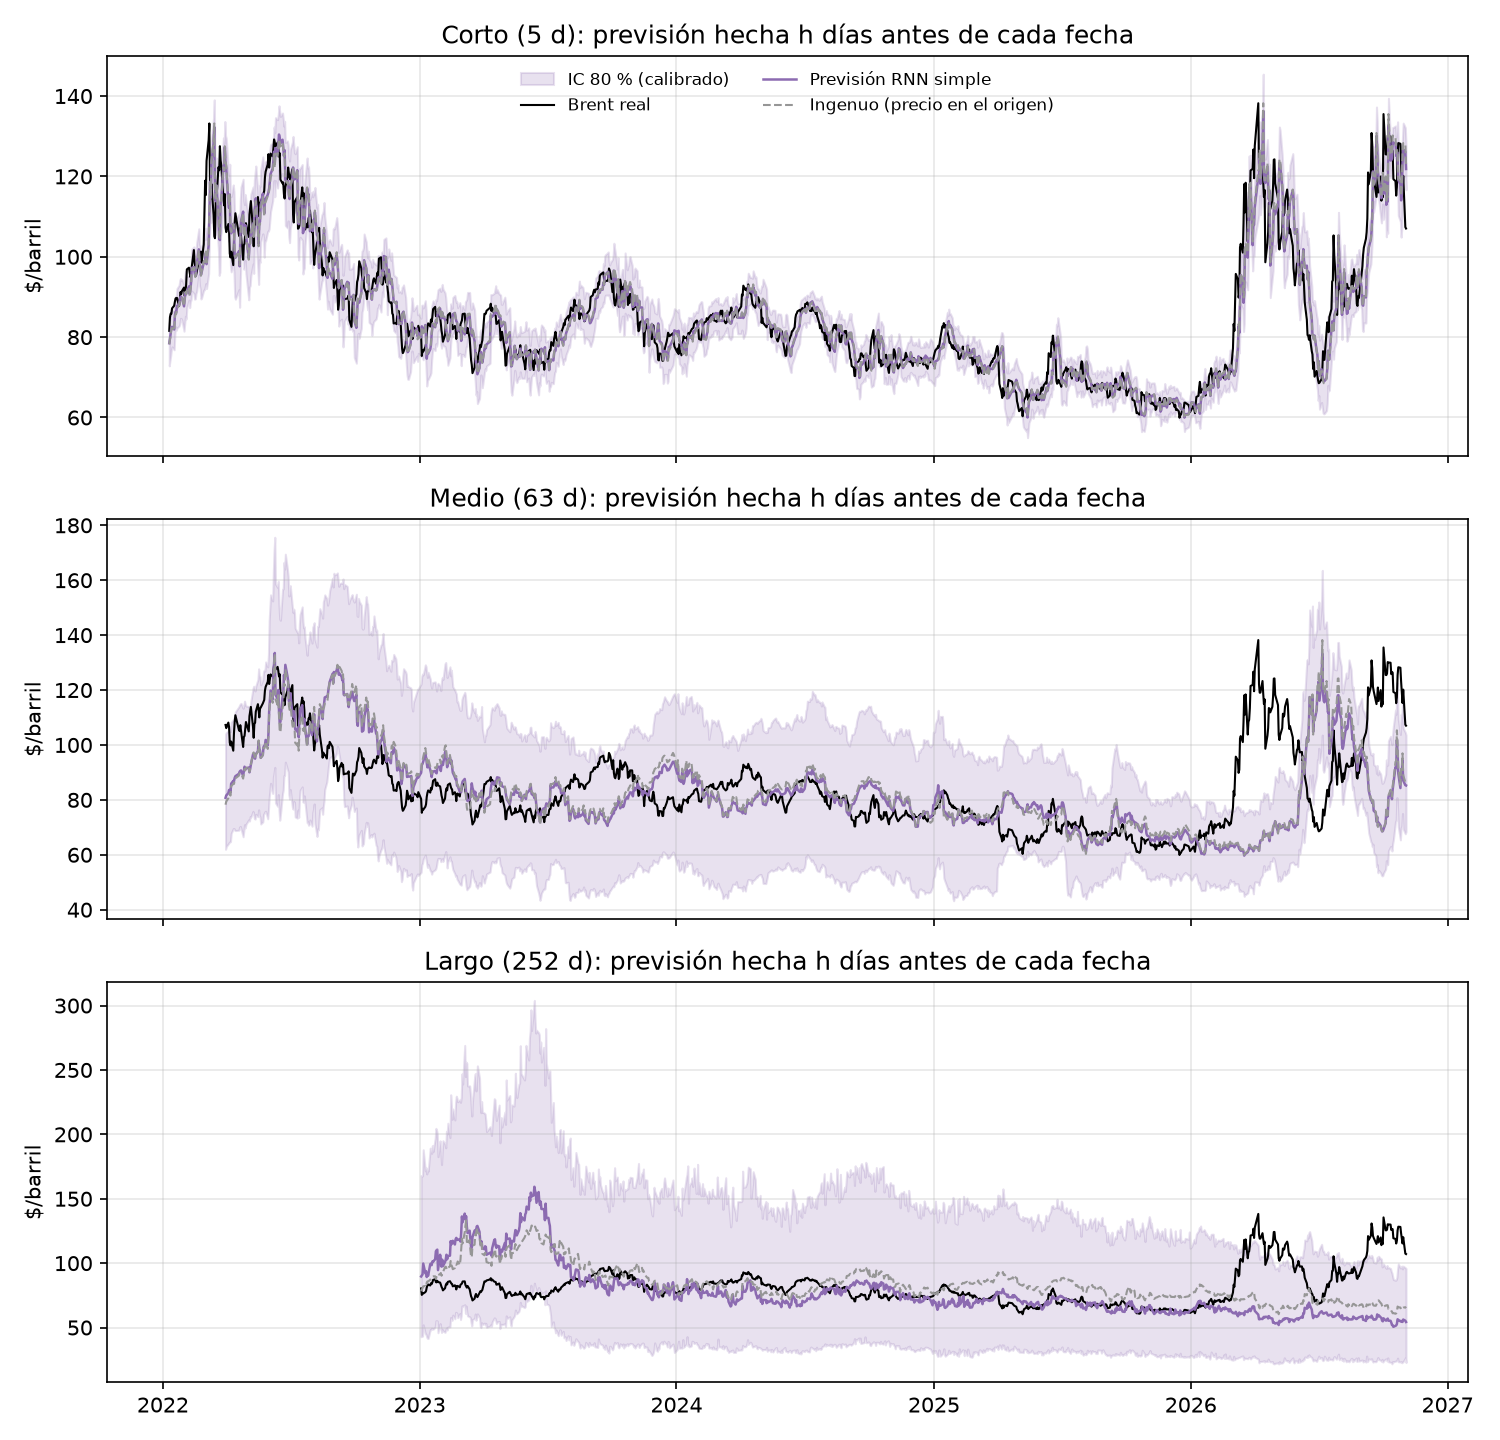

In [11]:
display(Image(paths.figures / "predicciones_test.png"))

## 7. Coste computacional

In [12]:
timing.pivot_table(
    index="arch", columns="horizon", values=["train_seconds", "n_params", "epochs"]
).round(1)

epochs               n_params                    train_seconds       \
horizon    5     63    252        5        63        252           5    63    
arch                                                                          
gru        2.0  37.0   2.0  1004807.0  11751.0   66887.0           0.4  3.2   
lstm       3.0   4.0   2.0  1339143.0  89031.0   89031.0           0.6  0.2   
rnn       25.0   7.0  10.0     5959.0  22599.0  204551.0           0.9  0.2   

              
horizon  252  
arch          
gru      0.1  
lstm     0.1  
rnn      0.7

## 8. Elección del modelo y conclusiones

In [13]:
print(selection["rule"])
pd.DataFrame(selection["scores"]).round(4)

regla fijada antes de ejecutar la ronda 2 (docs/experimento-ronda2.md): se elige la combinación de configuración y red con mayor mejora media del MAE frente al ingenuo en las predicciones anteriores a 2022 (reentrenos de 2014 a 2020), sin mirar el test. Ganó la RNN simple entrenada sin deriva y con recalibración del centro (+3,8 % antes de 2022).


,arch,mean_rel_mae,mean_rel_seed_std,mean_params,mean_coverage80
0,gru,0.9841,0.0509,361148.3333,0.8819
1,rnn,1.0065,0.0761,77703.0000,0.8545
2,lstm,1.0646,0.0563,505735.0000,0.8344


### Conclusiones

**Modelo elegido: RNN simple.** La red de la aplicación se fijó **antes de ver el test**, con la
regla de `docs/experimento-ronda2.md`: la combinación con mayor mejora media frente al ingenuo en
las predicciones anteriores a 2022 (RNN simple sin deriva y con recalibración, +3,8 %). En el test
la GRU queda algo mejor en conjunto (0,984 × MAE del ingenuo frente a 1,007 de la RNN simple),
pero cambiar la elección después de ver el test sería elegir mirando el examen. El coste de
entrenamiento es de segundos en GPU y de pocos minutos en CPU para las tres redes, así que no
condiciona la elección.

**Dónde aporta valor frente al ingenuo y dónde no** (RNN simple):

- **Corto plazo (5 días)**: +0,9 % de MAE, positiva en 4 de 5 años, **no significativa**
  (Diebold-Mariano p = 0,22). El intervalo del 80 % cubre el 79 % de los casos y es algo más
  informativo que el del ingenuo (Winkler 19,0 frente a 19,9).
- **Medio plazo (63 días)**: +4,0 % de MAE, positiva en 4 de 5 años, **no significativa**
  (p = 0,12). Las tres redes mejoran al ingenuo a este plazo (+3,3 % a +5,4 %). El intervalo es
  más ancho que el del ingenuo.
- **Largo plazo (252 días)**: **no mejora al ingenuo** (−6,8 % de MAE). Antes de 2022 la red
  acertaba a este plazo, pero en 2022-2026 la relación se invirtió (los picos de las guerras se
  deshicieron), algo que no se podía anticipar con los datos anteriores.

Es el resultado esperable para el crudo: con información de mercado pasada, el precio se
comporta casi como un paseo aleatorio, y el test (2022-2026) incluye dos shocks geopolíticos
imprevisibles. La aplicación muestra siempre el intervalo, dice en cada horizonte si el modelo
mejoró o no al «precio no cambia» y presenta la cifra central a largo plazo solo como referencia.

**Nota sobre la calibración**: el intervalo conformal usa todos los errores ya realizados
(ventana expansiva); con una ventana corta, a 252 días equivaldría a muy pocos años
independientes y daría intervalos degenerados.